## Kütüphaneler ve Ortam Hazırlığı

In [17]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Görselleştirme ayarları
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Figürlerin kaydedileceği klasör
os.makedirs("../figures", exist_ok=True)

## Veri Yükleme, Boyut ve Metadata İncelemesi

In [18]:
# Veri setini yükleme
df = pd.read_csv("../data/afad_earthquake_data_raw.csv")

# Sütun isimlerini normalize etme (küçük harf ve boşluksuz)
df.columns = df.columns.str.strip().str.lower()

# Tarih formatını parse etme
if "date" in df.columns:
    df["datetime"] = pd.to_datetime(df["date"])
elif "time" in df.columns:
    df["datetime"] = pd.to_datetime(df["time"])

print("--- Data Size & Dimensions ---")
print(f"Number of Instances: {df.shape[0]}")
print(f"Number of Attributes: {df.shape[1]}")
print("\n--- Attribute Data Types & Non-Null Counts ---")
print(df.info())

/var/folders/8l/0rb3s9ws4nj7tl0dxhycgyn00000gn/T/ipykernel_13263/3584613020.py:2: DtypeWarning: Columns (3: Latitude, 4: Longitude, 14: lastUpdateDate) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/afad_earthquake_data_raw.csv")
/var/folders/8l/0rb3s9ws4nj7tl0dxhycgyn00000gn/T/ipykernel_13263/3584613020.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df["date"])


--- Data Size & Dimensions ---
Number of Instances: 164940
Number of Attributes: 16

--- Attribute Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 164940 entries, 0 to 164939
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   rms             164940 non-null  float64       
 1   eventid         164940 non-null  int64         
 2   location        164939 non-null  str           
 3   latitude        164940 non-null  object        
 4   longitude       164940 non-null  object        
 5   depth           164940 non-null  float64       
 6   type            164940 non-null  str           
 7   magnitude       164940 non-null  float64       
 8   country         159568 non-null  str           
 9   province        154988 non-null  str           
 10  district        154988 non-null  str           
 11  neighborhood    128762 non-null  str           
 12  date            16494

## Eksik Veri Analizi (Missing Values)

In [19]:
# Eksik değer sayıları ve yüzdeleri
missing_df = pd.DataFrame(
    {
        "Missing Count": df.isnull().sum(),
        "Missing Percentage (%)": (df.isnull().sum() / len(df)) * 100,
    }
)

print("--- Missing Values Report ---")
print(missing_df.sort_values(by="Missing Count", ascending=False))

--- Missing Values Report ---
                Missing Count  Missing Percentage (%)
lastupdatedate         164004               99.432521
neighborhood            36178               21.934037
province                 9952                6.033709
district                 9952                6.033709
country                  5372                3.256942
location                    1                0.000606
rms                         0                0.000000
eventid                     0                0.000000
latitude                    0                0.000000
longitude                   0                0.000000
depth                       0                0.000000
type                        0                0.000000
magnitude                   0                0.000000
date                        0                0.000000
iseventupdate               0                0.000000
datetime                    0                0.000000


## Kategorik Değişken Analizi (Mode/Median & Bar Charts)

/var/folders/8l/0rb3s9ws4nj7tl0dxhycgyn00000gn/T/ipykernel_13263/2943274017.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
/var/folders/8l/0rb3s9ws4nj7tl0dxhycgyn00000gn/T/ipykernel_13263/2943274017.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=mag_type_col, order=order, palette="viridis")


--- Categorical Variables Summary ---
Feature: location | Unique Count: 38020 | Mode: Simav (Kütahya)
Feature: latitude | Unique Count: 72152 | Mode: 40.64
Feature: longitude | Unique Count: 102176 | Mode: 33.05
Feature: type | Unique Count: 7 | Mode: Md
Feature: country | Unique Count: 27 | Mode: Türkiye
Feature: province | Unique Count: 81 | Mode: Muğla
Feature: district | Unique Count: 868 | Mode: Tuşba
Feature: neighborhood | Unique Count: 12268 | Mode: Söğüt
Feature: date | Unique Count: 164821 | Mode: 8/5/2009 10:00:19 AM
Feature: lastupdatedate | Unique Count: 936 | Mode: 1/10/2023 11:06:09 AM


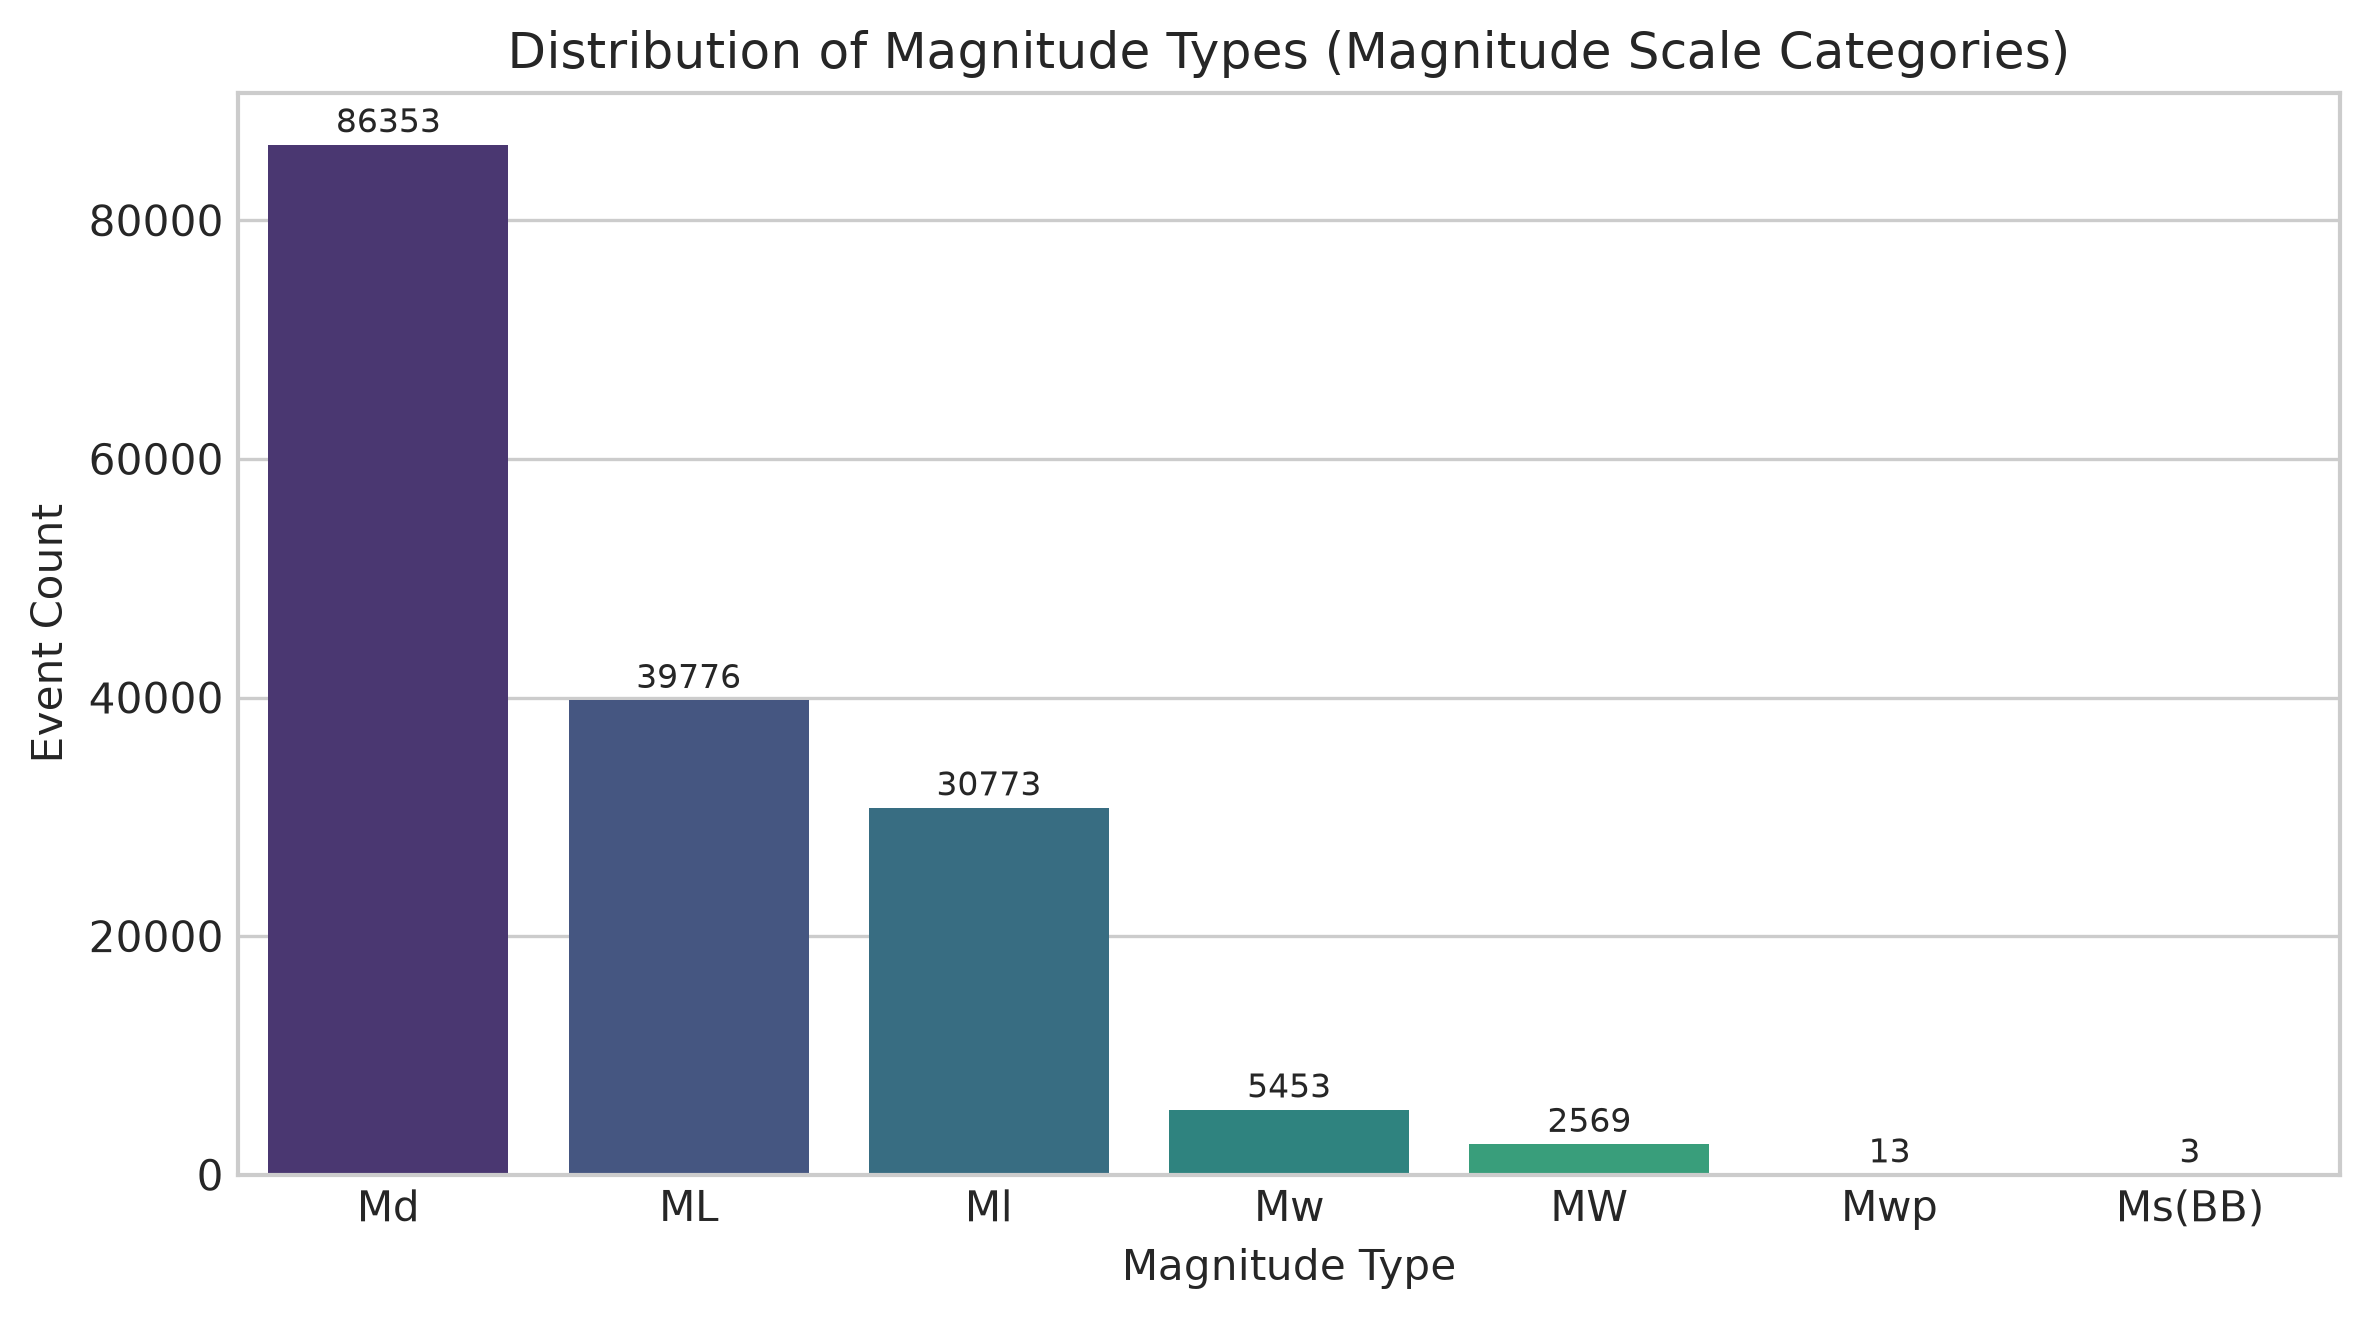

In [20]:
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
if "datetime" in categorical_cols:
    categorical_cols.remove("datetime")

print("--- Categorical Variables Summary ---")
for col in categorical_cols:
    mode_val = df[col].mode().iloc[0] if not df[col].mode().empty else "N/A"
    print(f"Feature: {col} | Unique Count: {df[col].nunique()} | Mode: {mode_val}")

# Magnitude Type (Tip) dağılımı (Bar Chart)
mag_type_col = next((c for c in ["type", "magnitudetype", "magtype"] if c in df.columns), None)
if mag_type_col:
    plt.figure(figsize=(8, 4.5))
    order = df[mag_type_col].value_counts().index
    ax = sns.countplot(data=df, x=mag_type_col, order=order, palette="viridis")
    plt.title("Distribution of Magnitude Types (Magnitude Scale Categories)", fontsize=12)
    plt.xlabel("Magnitude Type", fontsize=10)
    plt.ylabel("Event Count", fontsize=10)
    for p in ax.patches:
        ax.annotate(
            f"{int(p.get_height())}",
            (p.get_x() + p.get_width() / 2.0, p.get_height()),
            ha="center",
            va="center",
            xytext=(0, 5),
            textcoords="offset points",
            fontsize=8,
        )
    plt.tight_layout()
    plt.savefig("../figures/fig1_magnitude_type_distribution.png")
    plt.show()

## Sayısal Değişkenler İçin Box Plot Analizi

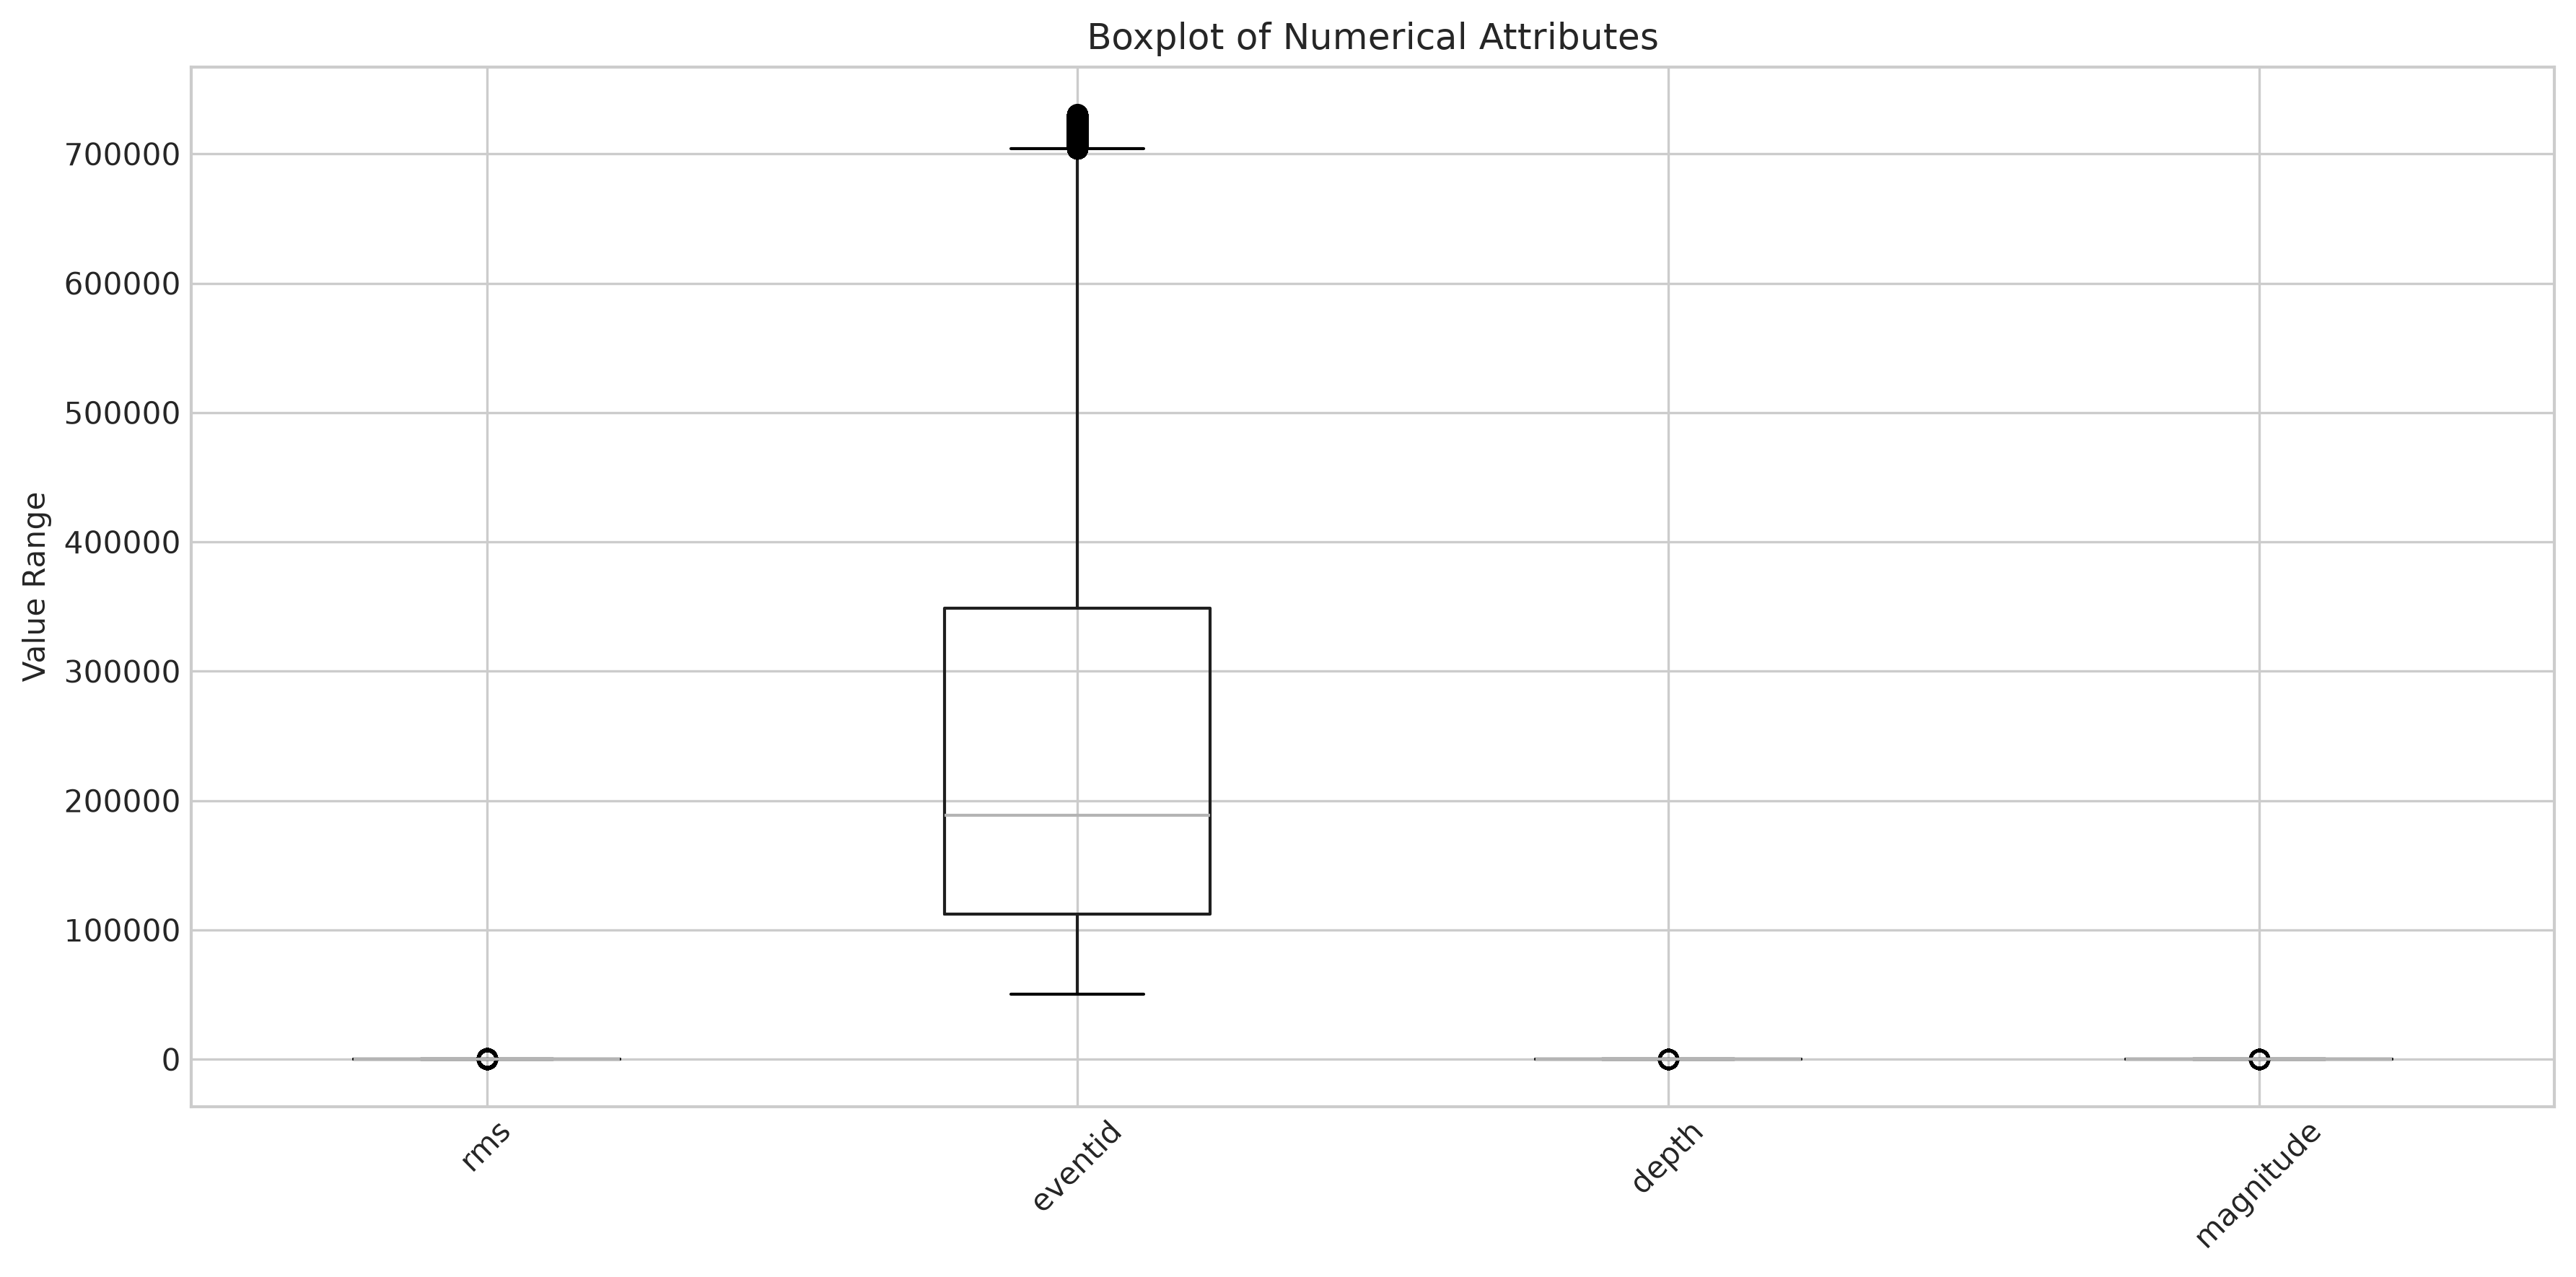

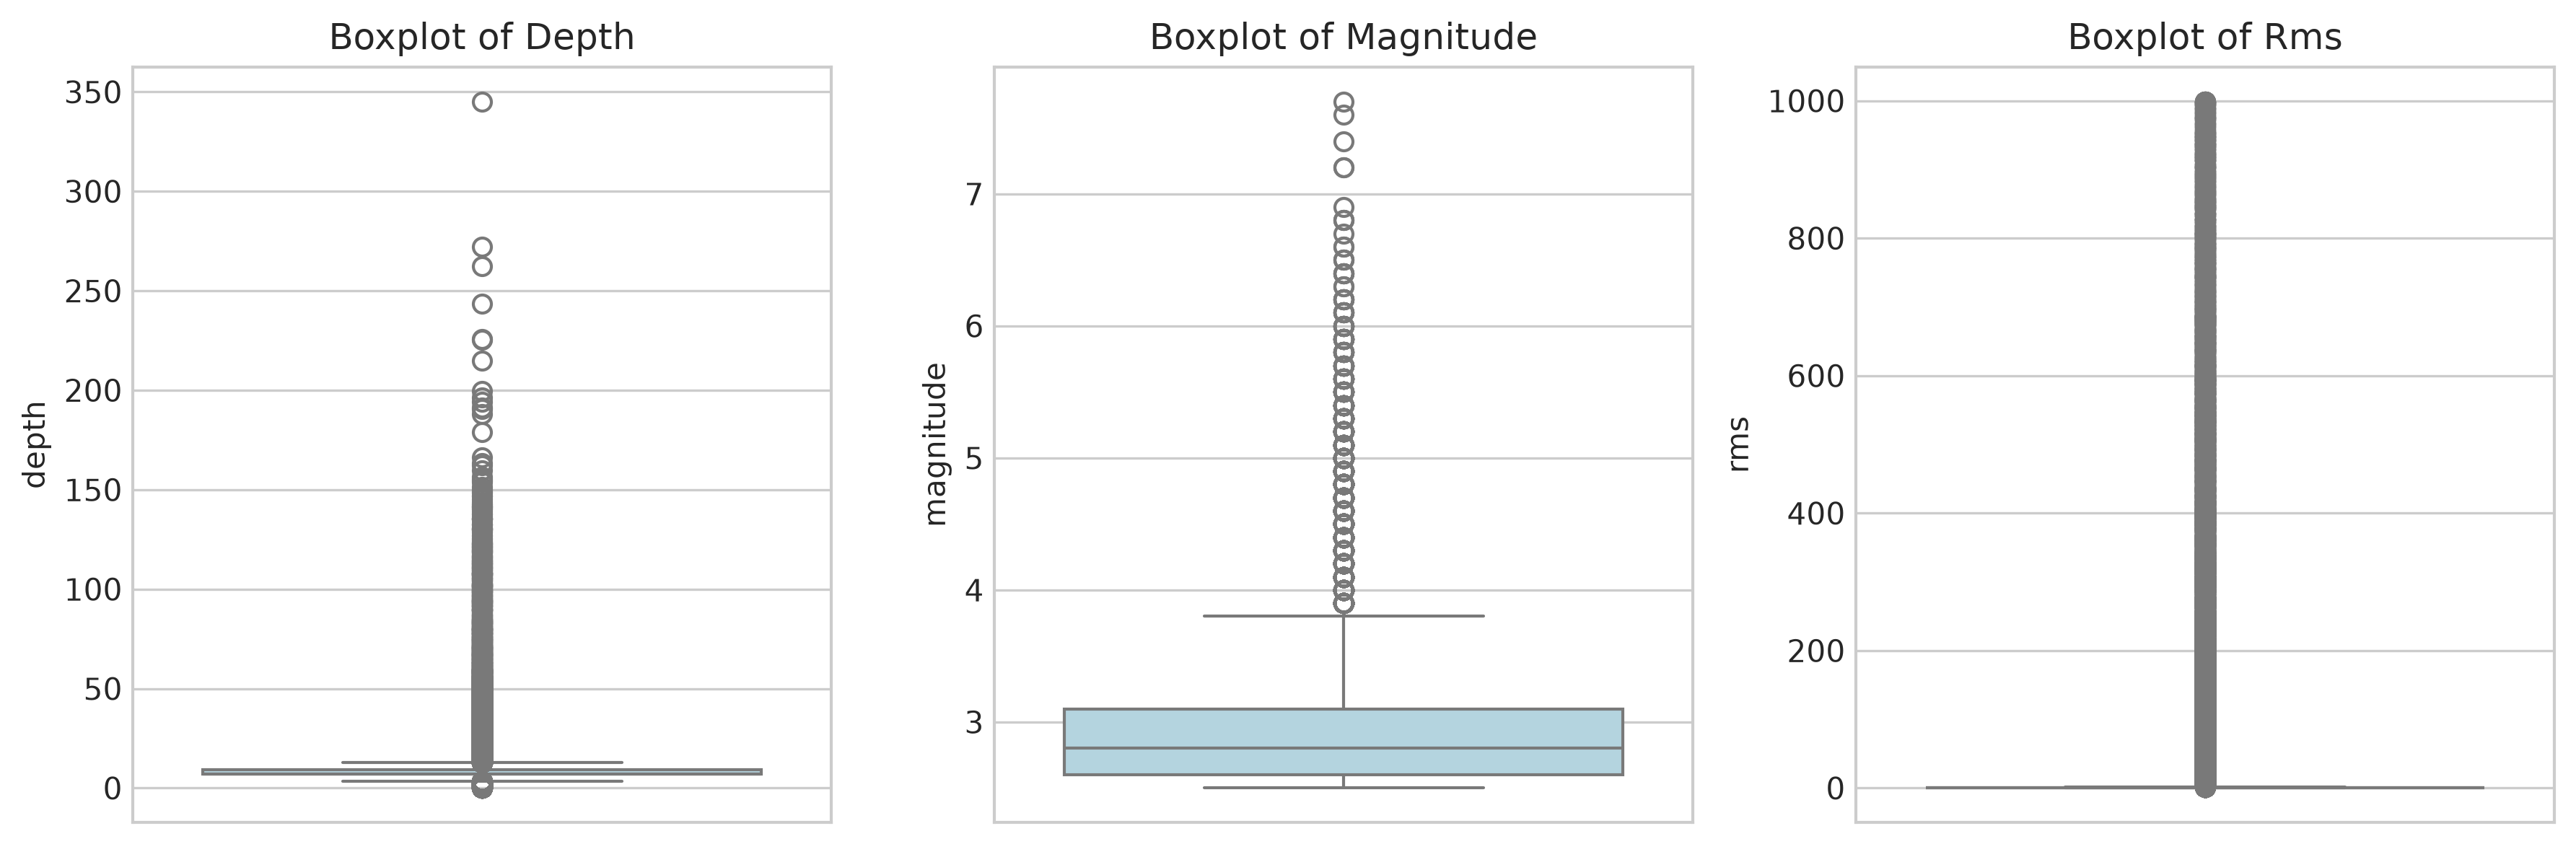

In [21]:
# Sayısal özelliklerin tespiti
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(12, 6))
df[numeric_cols].boxplot(rot=45)
plt.title("Boxplot of Numerical Attributes", fontsize=12)
plt.ylabel("Value Range", fontsize=10)
plt.tight_layout()
plt.savefig("../figures/fig2_numeric_boxplots.png")
plt.show()

# Depth ve Magnitude için odaklanmış box plot
focus_cols = [c for c in ["depth", "magnitude", "mag", "rms"] if c in df.columns]
if focus_cols:
    fig, axes = plt.subplots(1, len(focus_cols), figsize=(4 * len(focus_cols), 4))
    if len(focus_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, focus_cols):
        sns.boxplot(y=df[col], ax=ax, color="lightblue")
        ax.set_title(f"Boxplot of {col.capitalize()}")
        ax.set_ylabel(col)
    plt.tight_layout()
    plt.savefig("../figures/fig3_depth_mag_boxplot.png")
    plt.show()

## Ordinal / Sürekli Değişkenler İçin Histogramlar

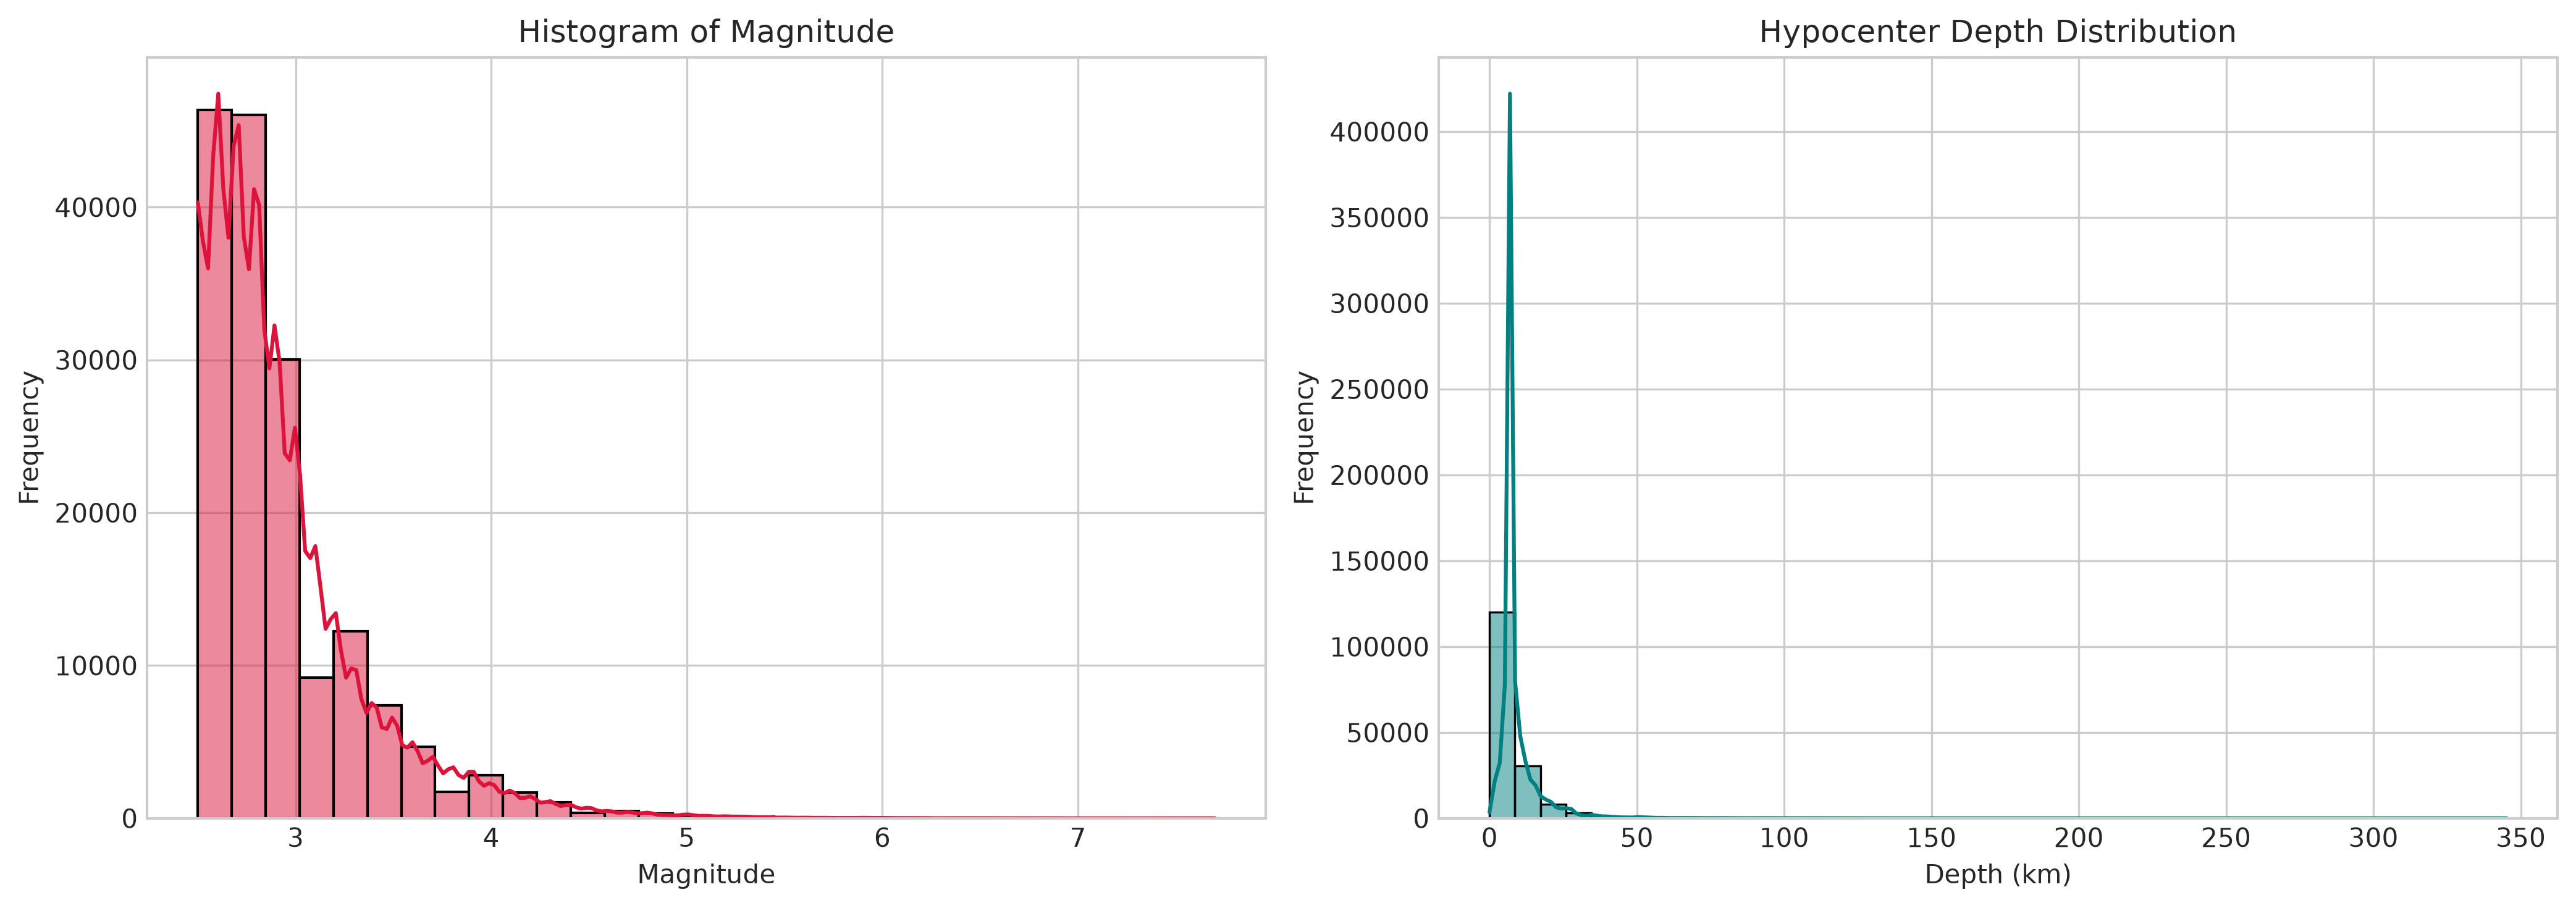

In [22]:
mag_col = next((c for c in ["magnitude", "mag", "ml", "mw"] if c in df.columns), None)
depth_col = next((c for c in ["depth", "derinlik"] if c in df.columns), None)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Magnitude Histogramı
if mag_col:
    sns.histplot(df[mag_col].dropna(), bins=30, kde=True, ax=axes[0], color="crimson")
    axes[0].set_title(f"Histogram of {mag_col.capitalize()}")
    axes[0].set_xlabel("Magnitude")
    axes[0].set_ylabel("Frequency")

# Depth Histogramı
if depth_col:
    sns.histplot(df[depth_col].dropna(), bins=40, kde=True, ax=axes[1], color="teal")
    axes[1].set_title("Hypocenter Depth Distribution")
    axes[1].set_xlabel("Depth (km)")
    axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("../figures/fig4_histograms.png")
plt.show()

## İkili İlişkiler (Scatter Plot)

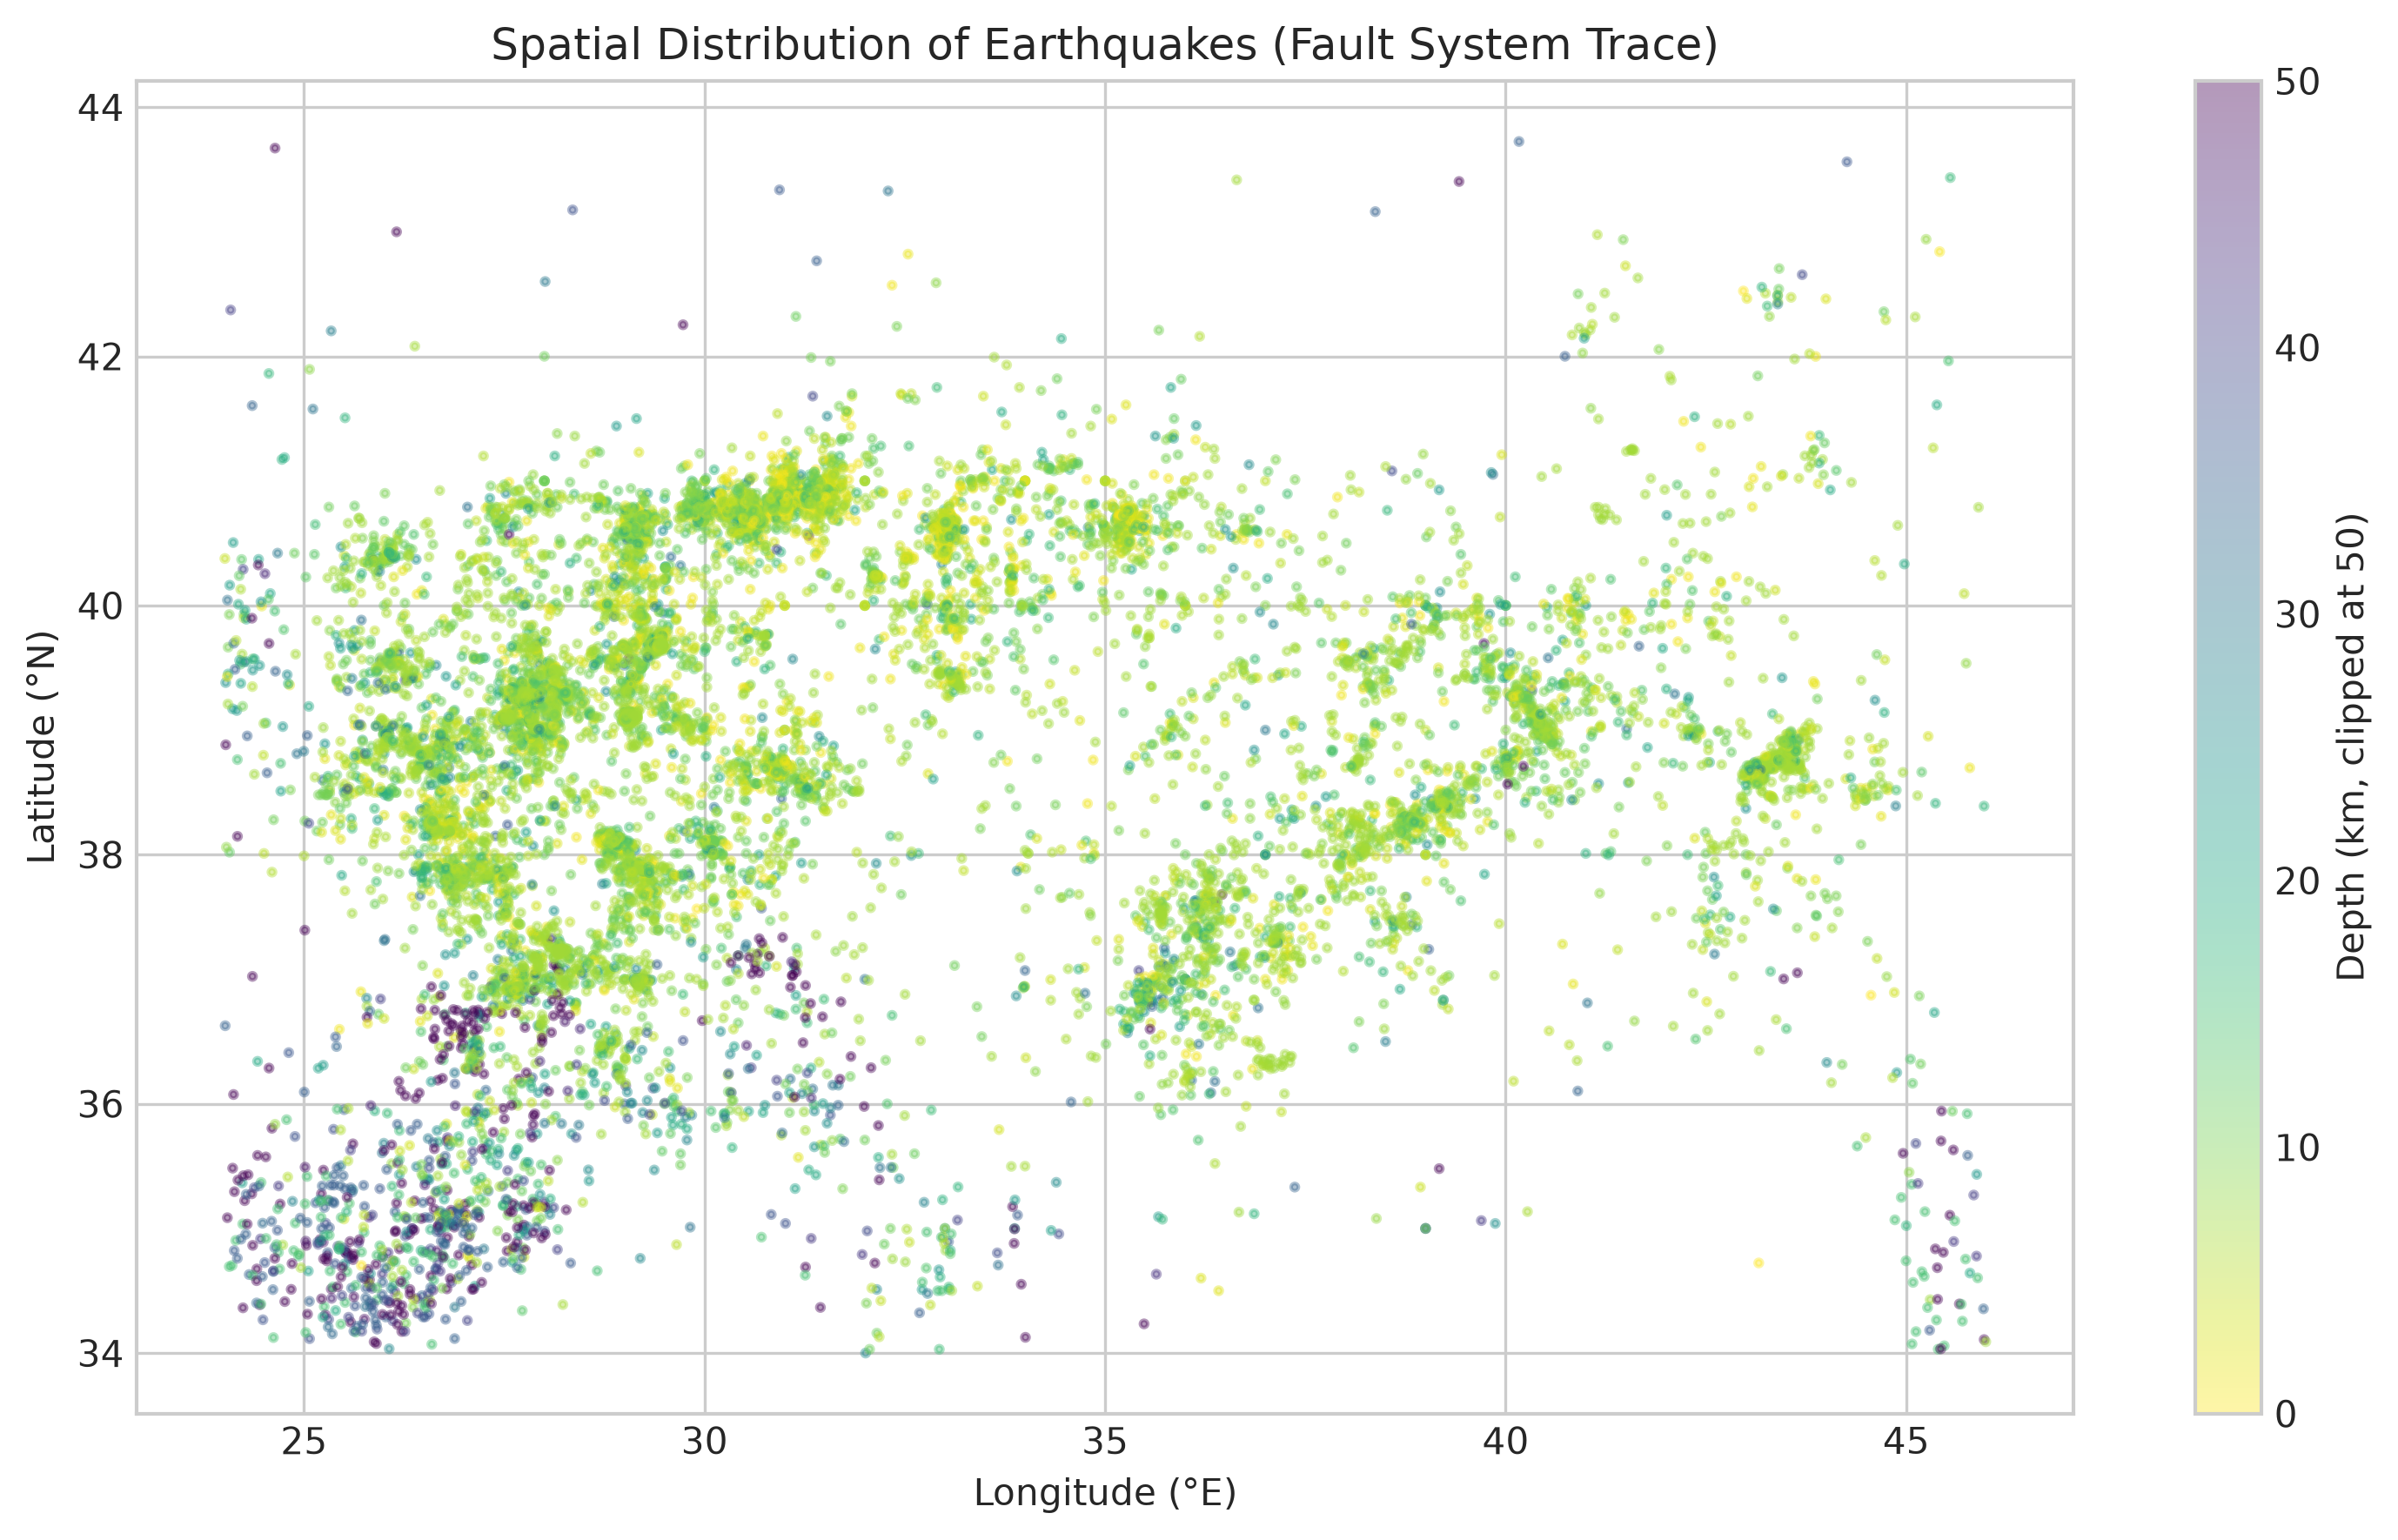

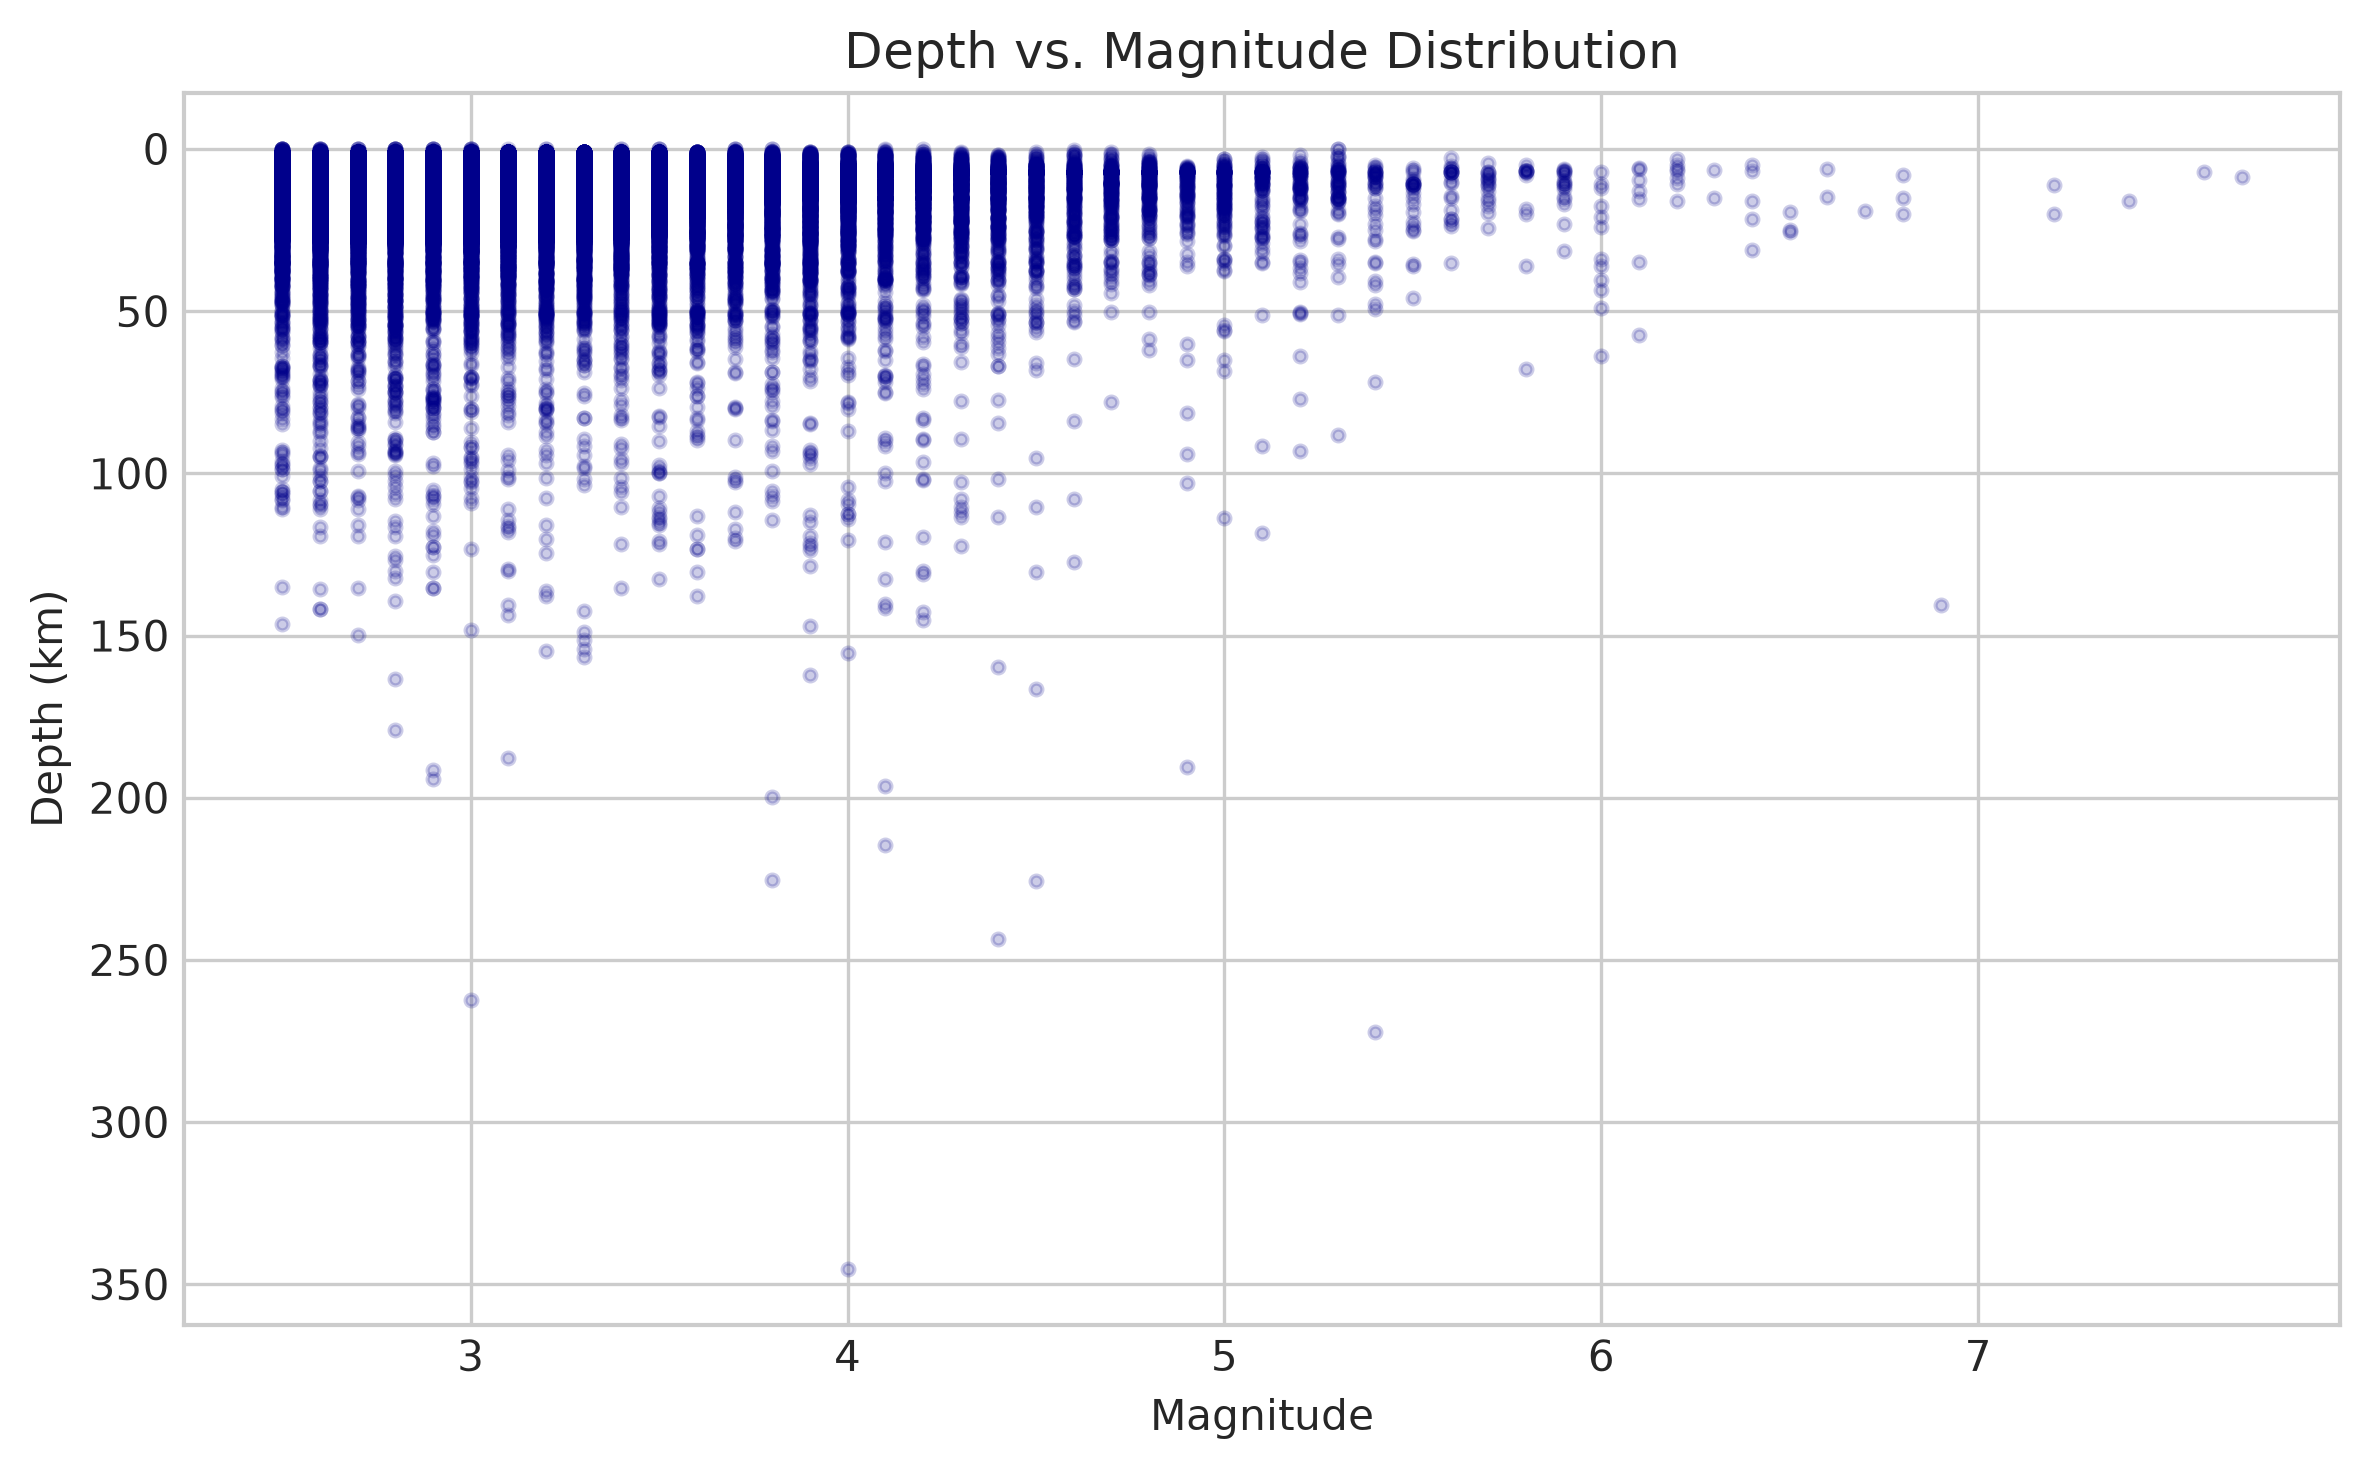

In [23]:
# Sayısal olması gereken sütunları temizleme ve float'a dönüştürme fonksiyonu
def clean_numeric_column(series):
    # String ise baştaki/sondaki boşlukları kaldır
    s = series.astype(str).str.strip()
    # Birden fazla nokta içeren ('2.673.361' gibi) bozuk formatları düzelt:
    # İlk noktayı koru, sonrakileri sil
    def fix_multiple_dots(val):
        if val.count(".") > 1:
            parts = val.split(".")
            return parts[0] + "." + "".join(parts[1:])
        return val

    s = s.apply(fix_multiple_dots)
    return pd.to_numeric(s, errors="coerce")

# Koordinat ve sayısal sütunları float formatına zorla
for col in [lat_col, lon_col, depth_col, mag_col]:
    if col and col in df.columns:
        df[col] = clean_numeric_column(df[col])

# Koordinatları Türkiye sınırları dışına taşan hatalı kayıtları filtrele
valid_mask = (
    df[lat_col].notnull() & 
    df[lon_col].notnull() & 
    df[depth_col].notnull() &
    df[lat_col].between(34.0, 44.0) & 
    df[lon_col].between(24.0, 46.0)
)
plot_df = df[valid_mask]

# 1. Mekânsal Dağılım (Latitude vs Longitude - Depth renklendirmeli)
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    plot_df[lon_col],
    plot_df[lat_col],
    c=plot_df[depth_col].clip(upper=50),
    cmap="viridis_r",
    s=4,
    alpha=0.4,
)
cbar = plt.colorbar(scatter)
cbar.set_label("Depth (km, clipped at 50)")
plt.xlabel("Longitude (°E)")
plt.ylabel("Latitude (°N)")
plt.title("Spatial Distribution of Earthquakes (Fault System Trace)")
plt.tight_layout()
plt.savefig("../figures/fig5_spatial_scatter.png")
plt.show()

# 2. Depth vs Magnitude İlişkisi
if depth_col and mag_col:
    mag_depth_df = df[df[depth_col].notnull() & df[mag_col].notnull()]
    plt.figure(figsize=(8, 5))
    plt.scatter(mag_depth_df[mag_col], mag_depth_df[depth_col], alpha=0.2, s=8, color="darkblue")
    plt.gca().invert_yaxis()
    plt.xlabel("Magnitude")
    plt.ylabel("Depth (km)")
    plt.title("Depth vs. Magnitude Distribution")
    plt.tight_layout()
    plt.savefig("../figures/fig6_depth_vs_magnitude.png")
    plt.show()

## Zamana Bağlı Analiz (Line Plot)

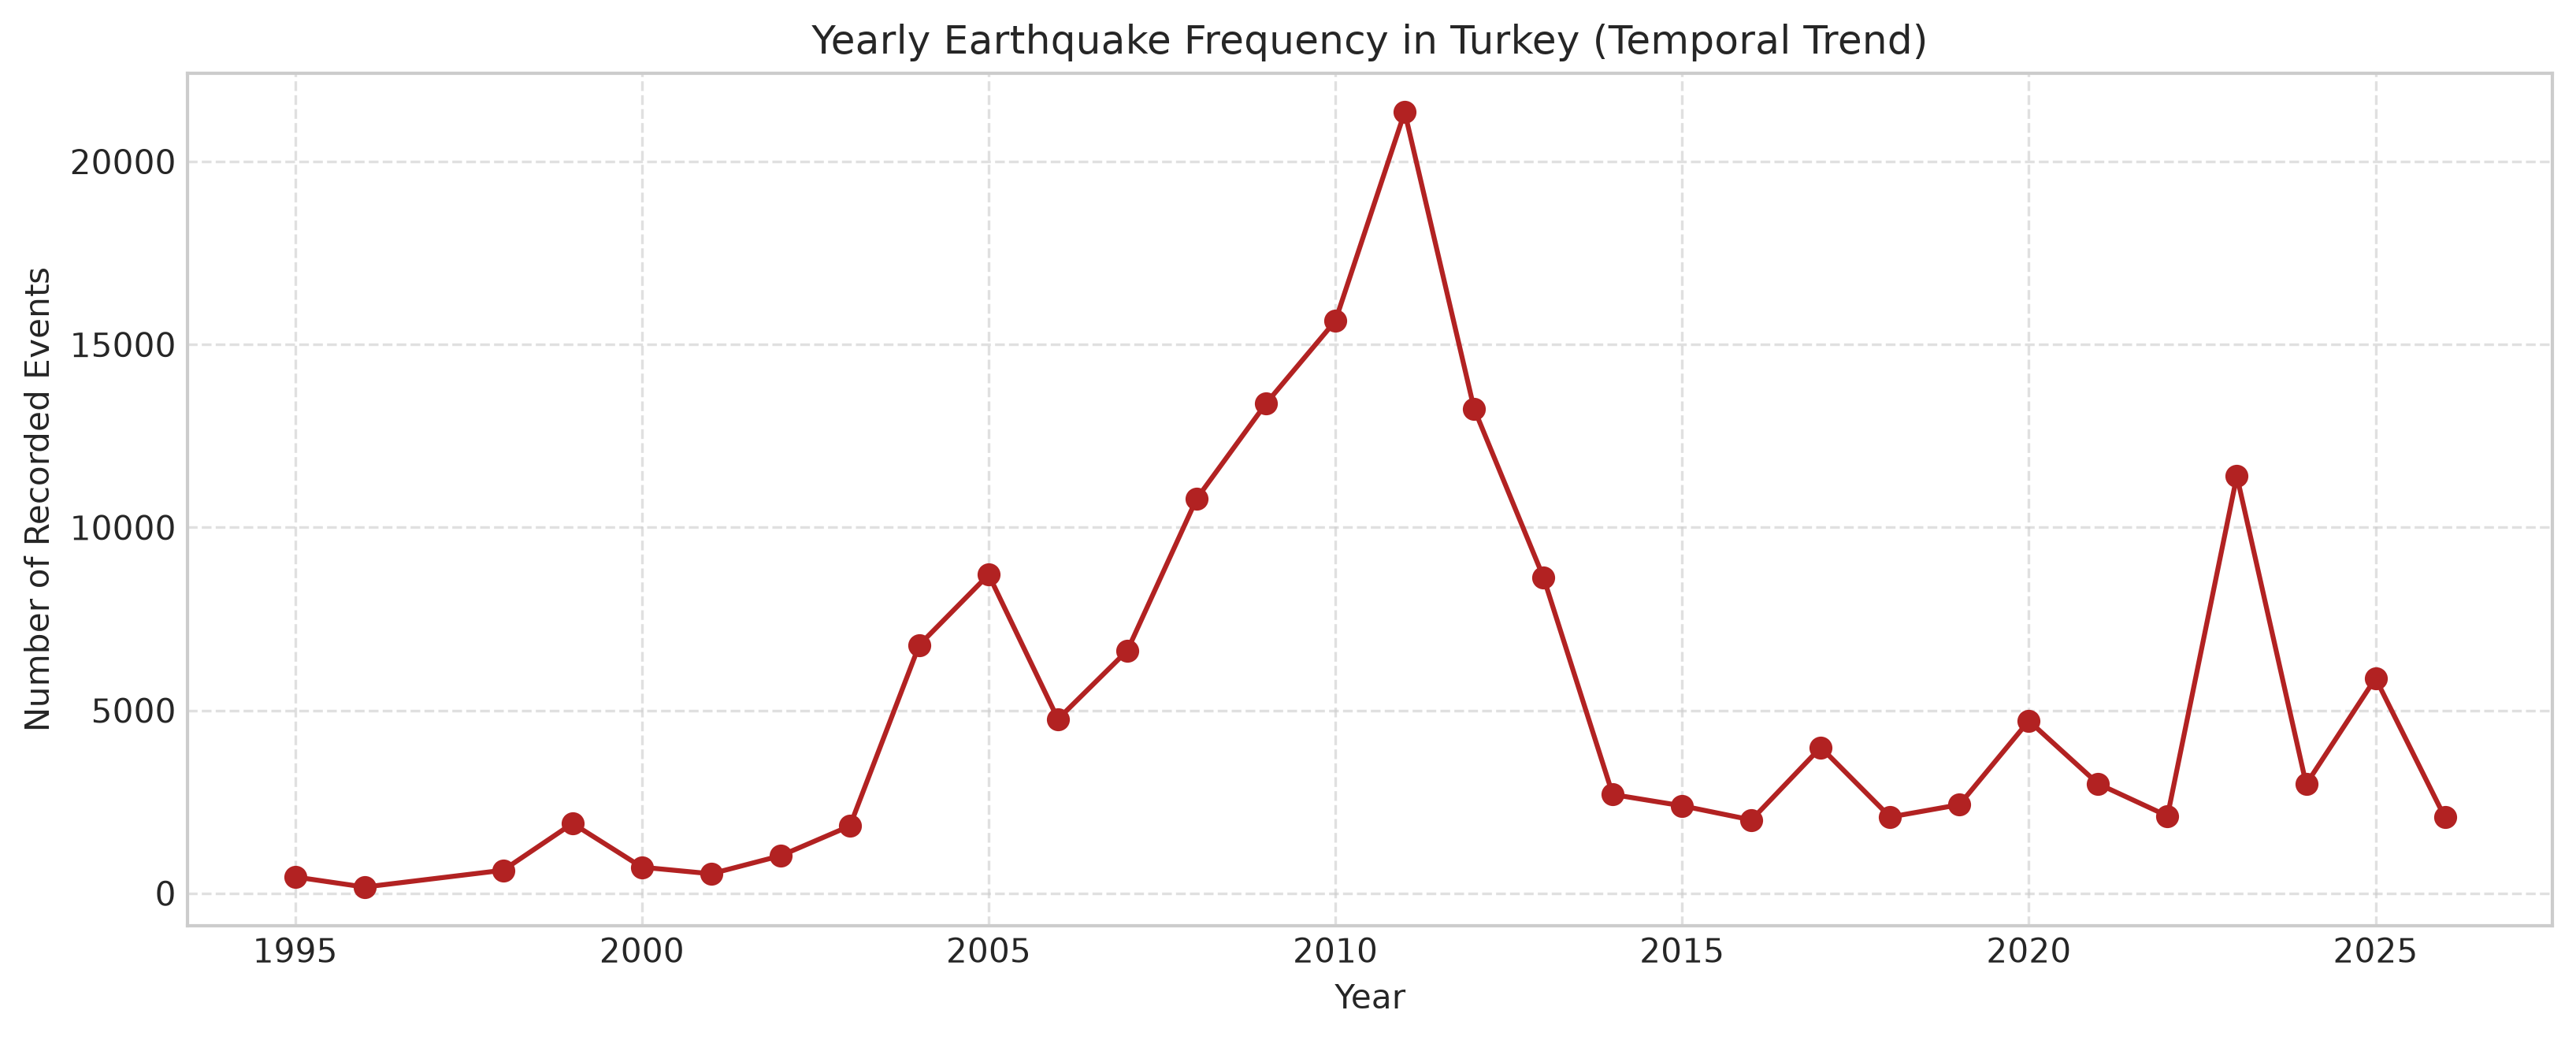

In [16]:
if "datetime" in df.columns:
    # Yıllık ve aylık deprem frekansı
    df["year"] = df["datetime"].dt.year
    events_per_year = df.groupby("year").size()

    plt.figure(figsize=(11, 4.5))
    events_per_year.plot(kind="line", marker="o", color="firebrick", linewidth=1.5)
    plt.title("Yearly Earthquake Frequency in Turkey (Temporal Trend)", fontsize=12)
    plt.xlabel("Year", fontsize=10)
    plt.ylabel("Number of Recorded Events", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.savefig("../figures/fig7_temporal_lineplot.png")
    plt.show()